Samajhna pehle: Recency, Frequency aur Monetary tumhare model ke features pehle se hain. Aaj unhe 1-5 ke scores aur business segments (Champions, At Risk, ...) mein badalna hai, taaki marketing team bina ML samjhe bhi customers ko samajh sake. Ek important cheez: tumhara churn label future window se bana hai, isliye segments ko us label se jaanch sakte ho. Yeh asli out-of-time validation hai.

Leakage ke 3 niyam (aaj bhi lagte hain):

1. RFM sirf cutoff se pehle ke data se bana hai (customer_ml_dataset.csv already aisa hai).
2. Score ke cut-offs sirf train customers se seekhe jaayenge, scaler ki tarah.
3. Test set aaj band rahega. Segments ka churn-check train par hoga.

1. Reusable code src/features/rfm.py:

In [1]:
"""RFM scoring (1-5) and rule-based segments. Reference distribution (train) se fit, kisi bhi data par apply."""
import numpy as np
import pandas as pd


def rfm_scores(values: pd.Series, reference: pd.Series, reverse: bool = False, k: int = 5) -> pd.Series:
    """Mid-rank percentile ke basis par 1..k score. Barabar values ko same score milta hai."""
    ref = np.sort(reference.to_numpy())
    v = values.to_numpy()
    left = np.searchsorted(ref, v, side='left')
    right = np.searchsorted(ref, v, side='right')
    p = (left + right) / (2 * len(ref))
    score = np.clip(np.ceil(p * k), 1, k).astype(int)
    if reverse:                      # Recency: kam din = behtar
        score = k + 1 - score
    return pd.Series(score, index=values.index)


def assign_segment(r: pd.Series, f: pd.Series, m: pd.Series) -> np.ndarray:
    conditions = [
        (r >= 4) & (f >= 4) & (m >= 4),
        (r >= 3) & (f >= 3),
        (r >= 4) & (f <= 2),
        (r <= 2) & (f >= 3),
        (r <= 2) & (f <= 2),
    ]
    names = ['Champions', 'Loyal', 'New / Promising', 'At Risk', 'Hibernating']
    return np.select(conditions, names, default='Need Attention')

Simple qcut ki jagah yeh approach isliye, kyunki Frequency mein bahut saare customers ke 1-2 orders hain. qcut duplicate edges par fail hota hai, aur ties ko alag scores de deta hai.

2. Data load karo aur Day 63 wala split reproduce karo:

In [5]:
import sys; sys.path.append('.')          # agar 'from src...' import error de
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sys
sys.path.append("../../")          # agar 'from src...' import error de
from sklearn.model_selection import train_test_split
from src.features.rfm import rfm_scores, assign_segment

feat = pd.read_csv('../../data/processed/customer_ml_dataset.csv')

idx_tr, idx_te = train_test_split(feat.index, test_size=0.2, random_state=42, stratify=feat['Churned'])
train = feat.loc[idx_tr].copy()

X_test_saved = pd.read_csv('../../data/processed/X_test.csv')
test_check = feat.loc[idx_te]
print("Split same hai:", np.allclose(test_check['Recency'].values, X_test_saved['Recency'].values))
print("Train customers:", len(train), "| churn rate:", round(train['Churned'].mean() * 100, 1), "%")

Split same hai: True
Train customers: 4226 | churn rate: 56.6 %


True aana chahiye. Agar False aaye, to split alag hai aur aage ke numbers par bharosa mat karo.

3. RFM scores (train se fit):

In [6]:
train['R'] = rfm_scores(train['Recency'], train['Recency'], reverse=True)
train['F'] = rfm_scores(train['Frequency'], train['Frequency'])
train['M'] = rfm_scores(train['Monetary'], train['Monetary'])

print(train[['R', 'F', 'M']].apply(lambda s: s.value_counts().sort_index()))

     R     F    M
1  846  1258  845
2  845   714  845
3  847   476  846
4  837   946  845
5  851   832  845


Table dekho. F ke levels barabar size ke nahi honge, kyunki ek hi Frequency value par bahut customers hain. Yeh bug nahi hai, data ki sachchai hai. README ya notes mein ek line likh do.

4. Segments banao:

In [7]:
train['Segment'] = assign_segment(train['R'], train['F'], train['M'])
print(train['Segment'].value_counts())

Segment
Hibernating        1223
Champions           986
Loyal               800
At Risk             468
New / Promising     376
Need Attention      373
Name: count, dtype: int64


Segment ke rules mere chune hue hain, koi universal standard nahi. Interview mein yeh bol sakte ho ki rules business ke saath tay hote hain.

5. Segment profile (customers, revenue share, churn):

In [8]:
seg = train.groupby('Segment').agg(
    customers=('Customer ID', 'count'),
    avg_recency=('Recency', 'mean'),
    avg_frequency=('Frequency', 'mean'),
    avg_monetary=('Monetary', 'mean'),
    total_monetary=('Monetary', 'sum'),
    churn_rate=('Churned', 'mean'),
)
seg['pct_customers'] = seg['customers'] / seg['customers'].sum() * 100
seg['pct_past_revenue'] = seg['total_monetary'] / seg['total_monetary'].sum() * 100
seg['churn_rate'] = seg['churn_rate'] * 100
seg = seg.drop(columns='total_monetary').sort_values('churn_rate')
print(seg.round(1))

                 customers  avg_recency  avg_frequency  avg_monetary  \
Segment                                                                
Champions              986         36.4           14.7        7463.0   
Loyal                  800        116.6            5.2        1914.2   
New / Promising        376         47.6            1.5         537.7   
At Risk                468        341.8            5.1        1830.1   
Need Attention         373        167.4            1.4         476.3   
Hibernating           1223        413.8            1.3         452.4   

                 churn_rate  pct_customers  pct_past_revenue  
Segment                                                       
Champions              20.1           23.3              68.9  
Loyal                  50.0           18.9              14.3  
New / Promising        51.6            8.9               1.9  
At Risk                68.8           11.1               8.0  
Need Attention         72.9            8.8   

Dhyan do: pct_past_revenue cutoff se pehle ki revenue ka share hai. Yeh future revenue nahi hai.

6. Sabse zaroori chart: kya segments sach mein churn alag-alag batate hain?

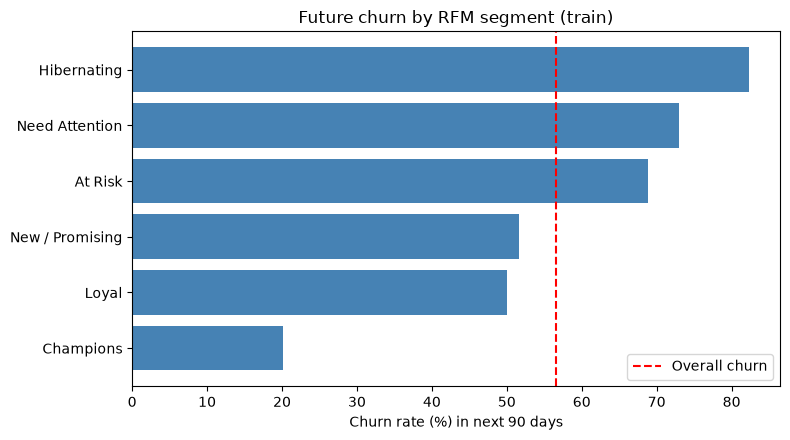

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(seg.index, seg['churn_rate'], color='steelblue')
ax.axvline(train['Churned'].mean() * 100, color='red', linestyle='--', label='Overall churn')
ax.set_xlabel('Churn rate (%) in next 90 days')
ax.set_title('Future churn by RFM segment (train)')
ax.legend()
plt.tight_layout()
plt.savefig('../../reports/rfm_segment_churn.png', dpi=150)
plt.show()

Kaise padho: Agar “Champions” ka churn rate “Hibernating” se saaf kam hai, to segmentation mein asli signal hai. Agar saare bars lagbhag barabar hain, to RFM tumhare data mein zyada kuch nahi batata, aur yeh bhi ek valid finding hai. Chart dekh kar segment rules ko tab tak mat badlo jab tak woh churn ko “behtar” na dikhaye. Rules label dekh kar adjust karna ek chhoti leakage hai.

7. Recency × Frequency heatmap (Day 55 ka skill):

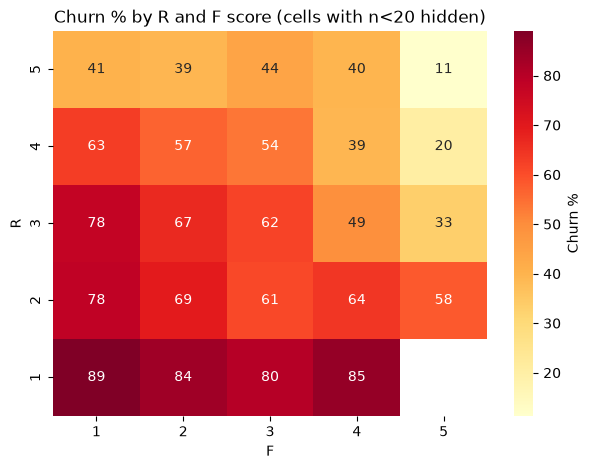

In [11]:
pv = train.pivot_table(index='R', columns='F', values='Churned', aggfunc='mean') * 100
cnt = train.pivot_table(index='R', columns='F', values='Churned', aggfunc='count')

plt.figure(figsize=(7, 5))
sns.heatmap(pv.where(cnt >= 20), annot=True, fmt='.0f', cmap='YlOrRd', cbar_kws={'label': 'Churn %'})
plt.gca().invert_yaxis()
plt.title('Churn % by R and F score (cells with n<20 hidden)')
plt.show()

Chhote cells (20 se kam customers) hide kiye, kyunki unka percentage misleading hota hai (Day 57 jaisa caution).

8. Revenue concentration (Pareto):

In [12]:
m = np.sort(train['Monetary'].values)[::-1]
cum = np.cumsum(m) / m.sum()
for top in [0.01, 0.05, 0.10, 0.20]:
    k = max(1, int(len(m) * top))
    print(f"Top {top:.0%} customers -> {cum[k - 1]:.1%} of past revenue")

Top 1% customers -> 28.0% of past revenue
Top 5% customers -> 48.6% of past revenue
Top 10% customers -> 61.3% of past revenue
Top 20% customers -> 75.6% of past revenue


Yeh ek business-friendly number hai (“top 20% customers 70% revenue dete hain”). Agar tumhara number bhi aisa hi nikla, to retention ko in customers par focus karna zyada samajhdari hai.

9. Ek design decision: kya RFM scores ko model ke features banana chahiye?

In [13]:
print("""
Nahi (is stage par). R, F, M scores raw Recency, Frequency, Monetary ke monotonic buckets hain.
Tree models (Random Forest, XGBoost) ke liye woh koi nayi information nahi dete,
aur LogReg ko bhi bahut kam milta hai. Upar se cut-offs ko CV ke har fold mein alag fit karna padega
(warna validation fold ki information cut-offs mein ghus jaayegi).
RFM yahan segmentation aur business storytelling ka tool hai.
Model ke liye nayi information Day 82 ke behavioral features se aayegi.
""")


Nahi (is stage par). R, F, M scores raw Recency, Frequency, Monetary ke monotonic buckets hain.
Tree models (Random Forest, XGBoost) ke liye woh koi nayi information nahi dete,
aur LogReg ko bhi bahut kam milta hai. Upar se cut-offs ko CV ke har fold mein alag fit karna padega
(warna validation fold ki information cut-offs mein ghus jaayegi).
RFM yahan segmentation aur business storytelling ka tool hai.
Model ke liye nayi information Day 82 ke behavioral features se aayegi.



Yeh decision README mein bhi jaayega. Interviewer ko dikhta hai ki tumne sochkar feature choose kiya.

10. Test likho (tests/test_rfm.py):

In [17]:
import numpy as np
import pandas as pd
import sys
import os
sys.path.append("../../")  # agar 'from
from src.features.rfm import rfm_scores, assign_segment


def test_scores_stay_in_range():
    ref = pd.Series(np.arange(100))
    s = rfm_scores(pd.Series([0, 50, 99, 500, -5]), ref)
    assert s.between(1, 5).all()


def test_recency_is_reversed():
    ref = pd.Series(np.arange(100))
    recent = rfm_scores(pd.Series([1]), ref, reverse=True).iloc[0]
    old = rfm_scores(pd.Series([99]), ref, reverse=True).iloc[0]
    assert recent == 5 and old == 1


def test_ties_get_same_score():
    ref = pd.Series([1] * 50 + list(range(2, 52)))
    s = rfm_scores(pd.Series([1, 1]), ref)
    assert s.nunique() == 1


def test_segment_rules():
    seg = assign_segment(pd.Series([5, 1]), pd.Series([5, 1]), pd.Series([5, 1]))
    assert list(seg) == ['Champions', 'Hibernating']

11. Segment table save karo:

In [20]:
seg.round(2).to_csv('../../reports/rfm_segments_train.csv')

practice questions:

1. Segment rules ke thresholds ko thoda badlo (jaise Champions mein >= 4 ki jagah >= 5) aur dekho ki segment sizes kaise badlte hain. Apne shabdon mein likho ki yeh sensitivity ek business ke liye kya matlab rakhti hai.

2. “At Risk” segment ke customers dhoondho (R kam, F zyada) aur likho ki unke liye ek retention message kaisa hona chahiye. Phir “New / Promising” ke liye alag message likho.